# Evaluasi Instance Segmentation — Panoptic Indoor v5

Notebook sederhana untuk memuat ekspor COCO, mengonversi anotasi polygon train/validation ke YOLO-seg, melatih YOLOv8n-seg, YOLO11n-seg, dan Mask R-CNN, mengevaluasi mask dengan pycocotools, lalu menampilkan prediksi.

Training tersedia tanpa test pribadi. Enam cell training terpisah; jalankan run yang dibutuhkan satu per satu. Cell unduh hanya berjalan bila dataset belum ada.

Catatan konversi: YOLO-seg menerima satu polygon per instance. Anotasi RLE atau multipart tidak bisa dikonversi tanpa kehilangan informasi dan akan ditolak untuk ekspor YOLO; Mask R-CNN tetap dapat membaca mask COCO tersebut.

## Blok 01 — Persiapan dan konfigurasi
Tujuan: impor pustaka dan menetapkan path/parameter. Input: tidak ada file proyek pendukung. Output: konfigurasi runtime. Jalankan ulang setelah restart kernel.

In [1]:
pip install roboflow

Note: you may need to restart the kernel to use updated packages.


In [23]:
from pathlib import Path
from collections import Counter, defaultdict
import importlib.metadata as metadata
import json, os, random, shutil, sys, subprocess, time

# Install only missing non-PyTorch packages; never replace Kaggle's CUDA torch stack.
REQUIRED_PACKAGES = {'numpy': 'numpy', 'pandas': 'pandas', 'yaml': 'PyYAML',
                     'matplotlib': 'matplotlib', 'PIL': 'Pillow',
                     'pycocotools': 'pycocotools', 'ultralytics': 'ultralytics'}
missing = [package for module, package in REQUIRED_PACKAGES.items()
           if __import__('importlib').util.find_spec(module) is None]
if missing:
    print('Menginstal dependensi non-PyTorch yang belum tersedia:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
try:
    import torch
    import torchvision
except ImportError as error:
    raise RuntimeError('Torch/torchvision tidak tersedia. Aktifkan image Kaggle dengan PyTorch; notebook sengaja tidak menginstal ulang keduanya.') from error

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import pil_to_tensor
from ultralytics import YOLO

SEED = 42
DATA_ROOT = Path('/kaggle/input/datasets/justditz/panoptic-indoor-segmentation')
DOWNLOAD_ROOT = Path('/kaggle/working/panoptic-indoor-v5')
OUTPUT_ROOT = Path('/kaggle/working/instance_segmentation')
PERSONAL_ROOT = Path('/kaggle/input/datasets/justditz/personal/train')
PERSONAL_METADATA = Path('/kaggle/input/datasets/justditz/metadata-personal-2/metadata_fixed.csv')
EPOCHS, IMAGE_SIZE, BATCH_SIZE = 10, 640, 2
NUM_WORKERS = 2 if os.name != 'nt' else 0
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
CHECKPOINT_PATHS_FILE = OUTPUT_ROOT / 'checkpoint_paths.json'

CHECKPOINT_PATHS = {
    'yolov8n_pretrained': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/8nbest.pt',
    'yolov8n_scratch': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/8nscr-best.pt',

    'yolo11n_pretrained': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/11nbest.pt',
    'yolo11n_scratch': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/11nscr-best.pt',

    'maskrcnn_pretrained': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/best_mask_ap_pretrained.pth',
    'maskrcnn_scratch': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/best_mask_ap_scratcj.pth',
}
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
versions = {'python': sys.version.split()[0], 'torch': torch.__version__,
            'torchvision': torchvision.__version__}
for package in ('numpy', 'pandas', 'PyYAML', 'matplotlib', 'Pillow', 'pycocotools', 'ultralytics'):
    try: versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError: versions[package] = 'unknown'
print('Versi library:', versions, '| device:', DEVICE)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'tidak tersedia')
print('Checkpoint tersimpan:', CHECKPOINT_PATHS)

RUN_TRAINING = False  # set True hanya jika ingin training ulang

Versi library: {'python': '3.13.16', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'numpy': '2.1.3', 'pandas': '2.3.3', 'PyYAML': '6.0.3', 'matplotlib': '3.10.0', 'Pillow': '13.0.0', 'pycocotools': '2.0.11', 'ultralytics': '8.4.218'} | device: cuda:0
GPU: Tesla T4
Checkpoint tersimpan: {'yolov8n_pretrained': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/8nbest.pt', 'yolov8n_scratch': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/8nscr-best.pt', 'yolo11n_pretrained': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/11nbest.pt', 'yolo11n_scratch': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/11nscr-best.pt', 'maskrcnn_pretrained': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/best_mask_ap_pretrained.pth', 'maskrcnn_scratch': '/kaggle/input/models/justditz/viskom-seg/pytorch/default/1/best_mask_ap_scratcj.pth'}


## Blok 02 — Dataset v5
Tujuan: gunakan ekspor v5 dengan split train/valid/test bawaan. Input: Kaggle Dataset atau Secret Roboflow. Output: DATA_ROOT. Jika dataset sudah dipasang sebagai Kaggle input, unduhan dilewati. Jalankan jika path input berubah.

In [3]:
if DATA_ROOT.is_dir():
    print('Memakai dataset yang sudah dipasang:', DATA_ROOT)
elif DOWNLOAD_ROOT.is_dir():
    DATA_ROOT = DOWNLOAD_ROOT
    print('Memakai unduhan sebelumnya:', DATA_ROOT)
else:
    from getpass import getpass
    try:
        from kaggle_secrets import UserSecretsClient
        api_key = yTCpFQezaozqA1zqaebu
    except Exception:
        api_key = getpass('Roboflow API key (input tersembunyi): ')
    if not api_key:
        raise ValueError('Tambahkan Secret ROBOFLOW_API_KEY atau unggah ekspor COCO v5 sebagai Kaggle Dataset.')
    from roboflow import Roboflow
    project = Roboflow(api_key=api_key).workspace('panopticindoor').project('panoptic-indoor-segmentation')
    downloaded = project.version(5).download(model_format='coco-segmentation', location=str(DOWNLOAD_ROOT))
    DATA_ROOT = Path(downloaded.location)
    del api_key
    print('Dataset diunduh ke:', DATA_ROOT)

Memakai dataset yang sudah dipasang: /kaggle/input/datasets/justditz/panoptic-indoor-segmentation


## Blok 03 — Muat split dan kategori COCO
Tujuan: membaca anotasi yang benar-benar tersedia tanpa membagi ulang data. Input: DATA_ROOT. Output: SPLITS dan daftar kategori dari ekspor. Jalankan setelah dataset siap.

In [15]:
def load_split(name):
    folder = DATA_ROOT / name
    files = list(folder.glob('_annotations.coco.json')) or list(folder.glob('*.json'))
    if len(files) != 1:
        raise FileNotFoundError(f'{folder}: perlu satu JSON COCO, ditemukan {len(files)}')
    annotation_file = files[0]
    with annotation_file.open(encoding='utf-8-sig') as handle: coco = json.load(handle)
    return {'name': name, 'root': folder, 'annotation_file': annotation_file,
            'coco': coco, 'api': COCO(str(annotation_file))}

valid_name = 'valid' if (DATA_ROOT / 'valid').is_dir() else 'val'
SPLITS = {name: load_split(folder) for name, folder in [('train', 'train'), ('valid', valid_name), ('test', 'test')]}
def category_signature(split):
    return sorted((int(category['id']), category['name']) for category in split['coco']['categories'])
train_signature = category_signature(SPLITS['train'])
for name, split in SPLITS.items():
    signature = category_signature(split)
    if signature != train_signature:
        raise ValueError(f'Kategori split {name} tidak konsisten dengan train. train={train_signature}; {name}={signature}. Evaluasi dihentikan agar mapping tidak tertukar.')
CATEGORIES = sorted(SPLITS['train']['coco']['categories'], key=lambda item: item['id'])
CLASS_IDS = [category['id'] for category in CATEGORIES]
CLASS_NAMES = [category['name'] for category in CATEGORIES]
COCO_TO_LABEL = {category_id: index for index, category_id in enumerate(CLASS_IDS)}
LABEL_TO_COCO = {index: category_id for category_id, index in COCO_TO_LABEL.items()}
for name, split in SPLITS.items():
    counts = Counter(annotation['category_id'] for annotation in split['coco']['annotations'])
    print(name, 'images=', len(split['coco']['images']), 'instances=', len(split['coco']['annotations']),
          'instances_by_class=', {category['name']: counts[category['id']] for category in CATEGORIES})
print('Kategori konsisten:', dict(zip(CLASS_IDS, CLASS_NAMES)))

def image_path(split, image):
    root = Path(split['root']).resolve()
    relative = Path(image['file_name'])
    if relative.is_absolute() or '..' in relative.parts:
        raise ValueError(f'file_name COCO harus relatif di dalam split: {image["file_name"]}')
    path = (root / relative).resolve()
    try: path.relative_to(root)
    except ValueError: raise ValueError(f'file_name COCO keluar dari root split: {image["file_name"]}') from None
    return path


loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
train images= 397 instances= 4479 instances_by_class= {'indoor-objects': 0, 'backpack': 3, 'bed': 26, 'blanket': 19, 'book': 105, 'bottle': 62, 'bowl': 65, 'box': 95, 'cabinet-merged': 47, 'cardboard': 2, 'ceiling-merged': 77, 'cell phone': 8, 'chair': 217, 'clock': 3, 'couch': 18, 'counter': 102, 'cup': 25, 'curtain': 3, 'dining table': 4, 'door-stuff': 64, 'fire-extinguisher': 29, 'floor-other-merged': 261, 'floor-wood': 99, 'flower': 0, 'food-other-merged': 127, 'fork': 4, 'hair drier': 0, 'handbag': 5, 'keyboard': 0, 'knife': 12, 'laptop': 8, 'light': 41, 'microwave': 3, 'mirror-stuff': 8, 'mouse': 0, 'oven': 3, 'pan': 225, 'paper': 28, 'paper-merged': 1, 'person': 192, 'pillow': 39, 'plate': 86, 'plug': 57, 'potted plant': 97, 'refriger

## Blok 04 — Konversi train/validation ke YOLO-seg
Tujuan: buat label polygon YOLO tanpa memasukkan test. Input: COCO train/valid. Output: folder dataset YOLO dan data.yaml. Jalankan sekali per sesi; gunakan folder output baru bila mengulang.

In [16]:
def polygon_to_yolo(annotation, width, height):
    segmentation = annotation['segmentation']
    if not isinstance(segmentation, list) or len(segmentation) != 1:
        raise ValueError(f'Anotasi {annotation.get("id")} bukan satu polygon; YOLO-seg tidak dapat mewakilinya tanpa kehilangan mask.')
    points = np.asarray(segmentation[0], dtype=float)
    if points.size < 6 or points.size % 2: raise ValueError(f'Polygon tidak valid pada anotasi {annotation.get("id")}')
    points = points.reshape(-1, 2)
    if not np.isfinite(points).all(): raise ValueError(f'Koordinat polygon non-finite pada anotasi {annotation.get("id")}')
    points[:, 0] /= width; points[:, 1] /= height
    if (points < 0).any() or (points > 1).any(): raise ValueError(f'Koordinat polygon di luar gambar pada anotasi {annotation.get("id")}')
    return str(COCO_TO_LABEL[annotation['category_id']]) + ' ' + ' '.join(f'{value:.6f}' for value in points.ravel())

unsupported = []
for split_name in ('train', 'valid'):
    for annotation in SPLITS[split_name]['coco']['annotations']:
        segmentation = annotation.get('segmentation')
        if not annotation.get('iscrowd', 0) and (not isinstance(segmentation, list) or len(segmentation) != 1):
            unsupported.append({'split': split_name, 'annotation_id': annotation.get('id'),
                                'kind': 'RLE' if isinstance(segmentation, dict) else 'multipart/invalid'})
print('Anotasi non-crowd tak terwakili YOLO:', len(unsupported), 'contoh:', unsupported[:10])
if unsupported:
    raise ValueError('Konversi dibatalkan: anotasi RLE/multipart tidak boleh dibuang otomatis. Gunakan pipeline mask COCO Mask R-CNN, atau siapkan ekspor polygon yang sudah ditinjau tanpa mengubah data sumber.')
crowd_count = sum(bool(a.get('iscrowd', 0)) for name in ('train', 'valid') for a in SPLITS[name]['coco']['annotations'])
print(f'Crowd annotations excluded from YOLO training targets: {crowd_count}')

YOLO_ROOT = OUTPUT_ROOT / 'yolo_coco_v5'
expected = {}
for split_name in ('train', 'valid'):
    source = SPLITS[split_name]
    expected[split_name] = [f'{index:07d}_{Path(image["file_name"]).name}' for index, image in enumerate(source['coco']['images'])]
if YOLO_ROOT.exists():
    yaml_path = YOLO_ROOT / 'data.yaml'
    missing_files = [relative for split_name, names in expected.items() for name in names
                     for relative in (f'images/{split_name}/{name}', f'labels/{split_name}/{Path(name).stem}.txt')
                     if not (YOLO_ROOT / relative).is_file()]
    if not yaml_path.is_file() or missing_files:
        raise RuntimeError(f'Folder konversi ada tetapi tidak lengkap ({len(missing_files)} file hilang; contoh {missing_files[:5]}). Tidak ditimpa/dihapus; atur YOLO_ROOT ke path baru setelah pemeriksaan manual.')
    YOLO_YAML = yaml_path
    print('Memakai ulang konversi lengkap yang ada:', YOLO_ROOT)
else:
    for split_name in ('train', 'valid'):
        source = SPLITS[split_name]
        images_dir, labels_dir = YOLO_ROOT / 'images' / split_name, YOLO_ROOT / 'labels' / split_name
        images_dir.mkdir(parents=True, exist_ok=False); labels_dir.mkdir(parents=True, exist_ok=False)
        image_by_id = {image['id']: image for image in source['coco']['images']}
        by_image = defaultdict(list)
        for annotation in source['coco']['annotations']:
            if not annotation.get('iscrowd', 0): by_image[annotation['image_id']].append(annotation)
        for index, image in enumerate(source['coco']['images']):
            source_path = image_path(source, image); destination = images_dir / f'{index:07d}_{source_path.name}'
            shutil.copy2(source_path, destination)
            lines = [polygon_to_yolo(a, image['width'], image['height']) for a in by_image[image['id']]]
            (labels_dir / f'{destination.stem}.txt').write_text('\n'.join(lines) + ('\n' if lines else ''),encoding='utf-8')
    YOLO_DATA = {'path': str(YOLO_ROOT), 'train': 'images/train', 'val': 'images/valid', 'names': CLASS_NAMES}
    YOLO_YAML = YOLO_ROOT / 'data.yaml'
    YOLO_YAML.write_text(yaml.safe_dump(YOLO_DATA, sort_keys=False, allow_unicode=True), encoding='utf-8')

print('YOLO dataset:', YOLO_ROOT, '| YAML:', YOLO_YAML)


Anotasi non-crowd tak terwakili YOLO: 0 contoh: []
Crowd annotations excluded from YOLO training targets: 0
Memakai ulang konversi lengkap yang ada: /kaggle/working/instance_segmentation/yolo_coco_v5
YOLO dataset: /kaggle/working/instance_segmentation/yolo_coco_v5 | YAML: /kaggle/working/instance_segmentation/yolo_coco_v5/data.yaml


## Blok 05 — Pratinjau ground truth
Tujuan: periksa beberapa mask COCO sebelum training. Input: split train. Output: visualisasi inline. Jalankan setelah Blok 03; tidak mengubah data.

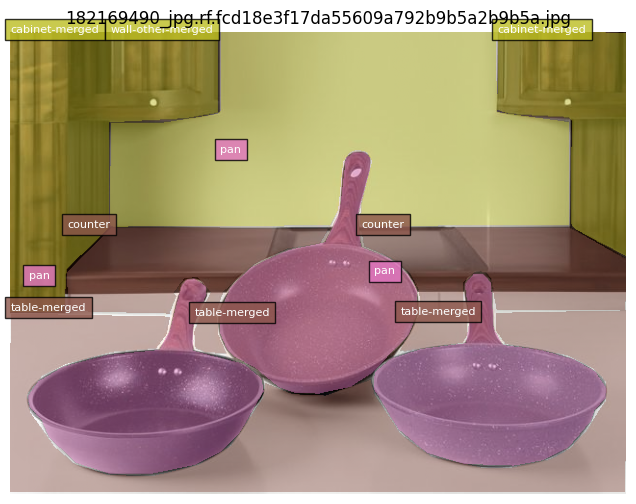

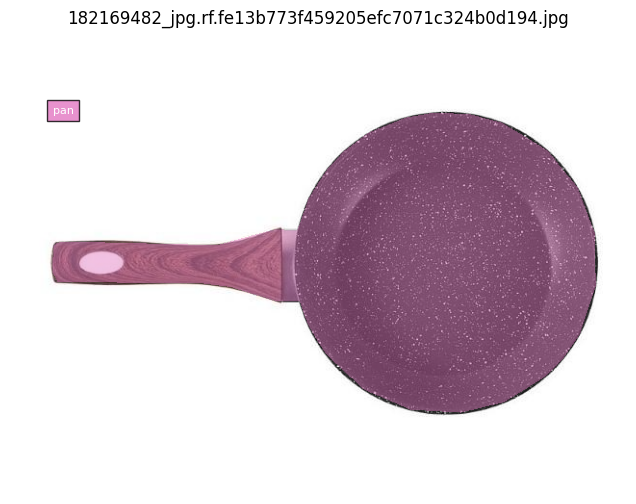

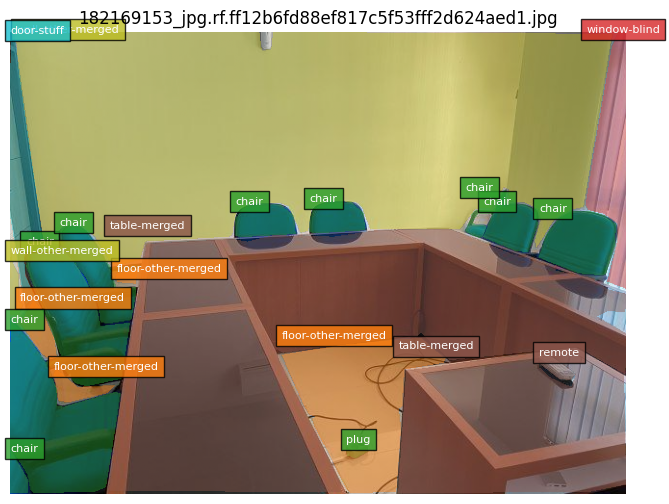

In [6]:
def show_ground_truth(split, count=3):
    records = split['coco']['images'][:count]
    for record in records:
        with Image.open(image_path(split, record)) as handle:
            image = handle.convert('RGB')
        annotations = [ann for ann in split['coco']['annotations'] if ann['image_id'] == record['id']]
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.imshow(image)
        for annotation in annotations:
            mask = split['api'].annToMask(annotation).astype(bool)
            color = plt.cm.tab10(COCO_TO_LABEL[annotation['category_id']] % 10)
            ax.imshow(np.ma.masked_where(~mask, mask), cmap=plt.matplotlib.colors.ListedColormap([color]), alpha=.45)
            ys, xs = np.where(mask)
            if len(xs):
                ax.text(xs.min(), ys.min(), CLASS_NAMES[COCO_TO_LABEL[annotation['category_id']]],
                        color='white', fontsize=8, bbox={'facecolor': color, 'alpha': .8})
        ax.set_title(record['file_name'])
        ax.axis('off')
        plt.show()

show_ground_truth(SPLITS['train'])

## Blok 06 — Training YOLOv8n-seg dan YOLO11n-seg
Tujuan: jalankan enam konfigurasi dalam cell terpisah. Input: YOLO_YAML dan parameter training. Output: log Ultralytics serta best.pt per run. Jalankan hanya cell run yang dipilih; framework menyimpan log/checkpoint standarnya. Pretrained memakai bobot COCO resmi; scratch mulai dari YAML tanpa pretrained.

In [7]:
YOLO_ARGS = {'data': str(YOLO_YAML), 'epochs': EPOCHS, 'imgsz': IMAGE_SIZE,
              'batch': BATCH_SIZE, 'device': DEVICE, 'workers': NUM_WORKERS,
              'seed': SEED, 'project': str(OUTPUT_ROOT / 'runs'),
              'plots': True, 'cache': False, 'verbose': True}
YOLO_CHECKPOINTS = {}

### YOLOv8n-seg — pretrained

In [ ]:
model = YOLO('yolov8n-seg.pt')
model.train(**YOLO_ARGS, name='yolov8n_pretrained', pretrained=True)
YOLO_CHECKPOINTS['yolov8n_pretrained'] = Path(model.trainer.best)
CHECKPOINT_PATHS['yolov8n_pretrained'] = str(YOLO_CHECKPOINTS['yolov8n_pretrained'])
CHECKPOINT_PATHS_FILE.write_text(json.dumps(CHECKPOINT_PATHS, indent=2), encoding='utf-8')
print(YOLO_CHECKPOINTS['yolov8n_pretrained'])

### YOLOv8n-seg — scratch

In [ ]:
model = YOLO('yolov8n-seg.yaml')
model.train(**YOLO_ARGS, name='yolov8n_scratch', pretrained=False)
YOLO_CHECKPOINTS['yolov8n_scratch'] = Path(model.trainer.best)
CHECKPOINT_PATHS['yolov8n_scratch'] = str(YOLO_CHECKPOINTS['yolov8n_scratch'])
CHECKPOINT_PATHS_FILE.write_text(json.dumps(CHECKPOINT_PATHS, indent=2), encoding='utf-8')
print(YOLO_CHECKPOINTS['yolov8n_scratch'])

### YOLO11n-seg — pretrained

In [ ]:
model = YOLO('yolo11n-seg.pt')
model.train(**YOLO_ARGS, name='yolo11n_pretrained', pretrained=True)
YOLO_CHECKPOINTS['yolo11n_pretrained'] = Path(model.trainer.best)
CHECKPOINT_PATHS['yolo11n_pretrained'] = str(YOLO_CHECKPOINTS['yolo11n_pretrained'])
CHECKPOINT_PATHS_FILE.write_text(json.dumps(CHECKPOINT_PATHS, indent=2), encoding='utf-8')
print(YOLO_CHECKPOINTS['yolo11n_pretrained'])

### YOLO11n-seg — scratch

In [ ]:
model = YOLO('yolo11n-seg.yaml')
model.train(**YOLO_ARGS, name='yolo11n_scratch', pretrained=False)
YOLO_CHECKPOINTS['yolo11n_scratch'] = Path(model.trainer.best)
CHECKPOINT_PATHS['yolo11n_scratch'] = str(YOLO_CHECKPOINTS['yolo11n_scratch'])
CHECKPOINT_PATHS_FILE.write_text(json.dumps(CHECKPOINT_PATHS, indent=2), encoding='utf-8')
print(YOLO_CHECKPOINTS['yolo11n_scratch'])

### Mask R-CNN — dataset dan training
Kedua run melatih seluruh backbone (5/5 layer trainable); hanya inisialisasi bobot berbeda. Pretrained memakai backbone/FPN COCO dengan head task baru, scratch acak. Keduanya memakai transform internal torchvision yang sama. Checkpoint dipilih hanya dari mask AP validation dalam eval mode; train loss, AP, durasi/epoch, waktu run, konfigurasi, GPU, CSV, dan best checkpoint disimpan per run. Perbedaan preprocessing/optimizer antarframework berarti delta tidak diatribusikan murni ke pretrained.


In [17]:
class CocoInstances(Dataset):
    def __init__(self, split):
        self.split, self.images = split, split['coco']['images']
        self.by_image = defaultdict(list)
        for annotation in split['coco']['annotations']:
            if not annotation.get('iscrowd', 0): self.by_image[annotation['image_id']].append(annotation)
    def __len__(self): return len(self.images)
    def __getitem__(self, index):
        record = self.images[index]
        with Image.open(image_path(self.split, record)) as handle: image = pil_to_tensor(handle.convert('RGB')).float() / 255
        height, width = image.shape[1:]
        boxes, labels, masks, areas = [], [], [], []
        for annotation in self.by_image[record['id']]:
            x, y, box_width, box_height = annotation['bbox']
            if box_width <= 0 or box_height <= 0: continue
            mask = self.split['api'].annToMask(annotation)
            if not mask.any(): continue
            boxes.append([x, y, x + box_width, y + box_height]); labels.append(COCO_TO_LABEL[annotation['category_id']] + 1)
            masks.append(mask); areas.append(float(mask.sum()))
        target = {'boxes': torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                  'labels': torch.tensor(labels, dtype=torch.int64),
                  'masks': torch.as_tensor(np.stack(masks) if masks else np.zeros((0, height, width), dtype=np.uint8), dtype=torch.uint8),
                  'image_id': torch.tensor([record['id']]), 'area': torch.tensor(areas, dtype=torch.float32),
                  'iscrowd': torch.zeros(len(labels), dtype=torch.int64)}
        return image, target

def collate_fn(batch): return tuple(zip(*batch))
def encode_mask(mask):
    rle = mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))
    return {'size': [int(v) for v in rle['size']], 'counts': rle['counts'].decode('ascii')}

def build_maskrcnn(pretrained, score_threshold=0.001, nms_threshold=0.7, max_detections=100):
    if pretrained:
        model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT)
        box_features = model.roi_heads.box_predictor.cls_score.in_features
        mask_features = model.roi_heads.mask_predictor.conv5_mask.in_channels
        model.roi_heads.box_predictor = FastRCNNPredictor(box_features, len(CATEGORIES) + 1)
        model.roi_heads.mask_predictor = MaskRCNNPredictor(mask_features, 256, len(CATEGORIES) + 1)
    else:
        model = maskrcnn_resnet50_fpn(weights=None, weights_backbone=None, num_classes=len(CATEGORIES) + 1)
    model.roi_heads.score_thresh = score_threshold
    model.roi_heads.nms_thresh = nms_threshold
    model.roi_heads.detections_per_img = max_detections
    # Both runs train every backbone layer; only pretrained run starts from COCO weights.
    for parameter in model.backbone.parameters(): parameter.requires_grad = True
    return model

def maskrcnn_predictions(model, split):
    predictions = []
    with torch.inference_mode():
        for record in split['coco']['images']:
            with Image.open(image_path(split, record)) as handle:
                image = pil_to_tensor(handle.convert('RGB')).float().div_(255).to(DEVICE)
            result = model([image])[0]
            for index, score in enumerate(result['scores']):
                if float(score) < 0.001: continue
                label = int(result['labels'][index]) - 1
                predictions.append({'image_id': record['id'], 'category_id': LABEL_TO_COCO[label],
                                    'segmentation': encode_mask(result['masks'][index, 0].cpu().numpy() >= 0.5),
                                    'score': float(score)})
    return predictions

def validation_mask_ap(split, predictions):
    ground_truth = split['api']
    if predictions: detections = ground_truth.loadRes(predictions)
    else:
        detections = COCO(); detections.dataset = {'images': ground_truth.dataset['images'],
            'categories': ground_truth.dataset['categories'], 'annotations': []}; detections.createIndex()
    evaluator = COCOeval(ground_truth, detections, 'segm')
    evaluator.params.catIds = CLASS_IDS; evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize()
    return float(evaluator.stats[0])

def train_maskrcnn(pretrained, run_name):
    started = time.time(); started_iso = time.strftime('%Y-%m-%dT%H:%M:%S%z')
    model = build_maskrcnn(pretrained).to(DEVICE)
    train_loader = DataLoader(CocoInstances(SPLITS['train']), batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, collate_fn=collate_fn)
    valid_loader = DataLoader(CocoInstances(SPLITS['valid']), batch_size=1, shuffle=False,
                              num_workers=NUM_WORKERS, collate_fn=collate_fn)
    optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=0.005, momentum=0.9, weight_decay=0.0005)
    run_dir = OUTPUT_ROOT / 'maskrcnn_runs' / run_name
    run_dir.mkdir(parents=True, exist_ok=True)
    checkpoint = run_dir / 'best_mask_ap.pth'; log_path = run_dir / 'training.csv'
    config = {'model': 'Mask R-CNN ResNet50-FPN', 'pretrained': pretrained, 'trainable_backbone_layers': 5,
              'all_backbone_parameters_trainable': True, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
              'learning_rate': 0.005, 'optimizer': 'SGD', 'momentum': 0.9, 'weight_decay': 0.0005,
              'seed': SEED, 'device': DEVICE, 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
              'normalization': 'torchvision GeneralizedRCNNTransform mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]; input RGB float [0,1]',
              'preprocessing': 'torchvision internal resize (min_size=800,max_size=1333); same for both variants',
              'pretrained_initialization': 'torchvision COCO backbone/FPN then random task heads' if pretrained else 'random backbone/FPN and task heads',
              'validation_metric': 'COCO mask AP@[.50:.95], model.eval(), inference_mode()',
              'inference_thresholds': {'score': 0.001, 'nms_iou': 0.7, 'max_detections': 100}}
    (run_dir / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    rows = []; best_ap = -float('inf')
    for epoch in range(EPOCHS):
        epoch_started = time.time(); model.train(); train_total = 0.0
        for images, targets in train_loader:
            images = [image.to(DEVICE) for image in images]
            targets = [{key: value.to(DEVICE) for key, value in target.items()} for target in targets]
            losses = model(images, targets); loss = sum(losses.values())
            optimizer.zero_grad(); loss.backward(); optimizer.step(); train_total += float(loss.detach().cpu())
        train_loss = train_total / max(1, len(train_loader))
        model.eval()
        valid_predictions = maskrcnn_predictions(model, SPLITS['valid'])
        valid_ap = validation_mask_ap(SPLITS['valid'], valid_predictions)
        duration = time.time() - epoch_started
        rows.append({'epoch': epoch + 1, 'train_loss': train_loss, 'validation_mask_ap': valid_ap, 'duration_seconds': duration})
        pd.DataFrame(rows).to_csv(log_path, index=False)
        print(f'{run_name} epoch {epoch+1}/{EPOCHS}: train_loss={train_loss:.4f} valid_mask_ap={valid_ap:.4f} duration={duration:.1f}s')
        if np.isfinite(valid_ap) and valid_ap > best_ap:
            best_ap = valid_ap; torch.save(model.state_dict(), checkpoint)
    finished = time.time()
    config.update({'started_at': started_iso, 'finished_at': time.strftime('%Y-%m-%dT%H:%M:%S%z'),
                   'duration_seconds': finished - started, 'best_validation_mask_ap': best_ap,
                   'checkpoint': str(checkpoint) if checkpoint.is_file() else None})
    (run_dir / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    if not checkpoint.is_file(): raise RuntimeError(f'Tidak ada checkpoint validasi yang tersimpan untuk {run_name}; periksa metrik validation.')
    CHECKPOINT_PATHS[run_name] = str(checkpoint)
    CHECKPOINT_PATHS_FILE.write_text(json.dumps(CHECKPOINT_PATHS, indent=2), encoding='utf-8')
    return checkpoint

MASK_CHECKPOINTS = {}

print("Ready")

Ready


### Mask R-CNN — pretrained

In [ ]:
MASK_CHECKPOINTS['maskrcnn_pretrained'] = train_maskrcnn(True, 'maskrcnn_pretrained')

### Mask R-CNN — scratch

In [ ]:
MASK_CHECKPOINTS['maskrcnn_scratch'] = train_maskrcnn(False, 'maskrcnn_scratch')

## Blok 07 — Prediksi dan evaluasi mask COCO
Tujuan: mengevaluasi checkpoint yang telah dilatih dengan satu evaluator pycocotools. Input: checkpoint dan split test asli. Output: AP@[.50:.95], AP50, AP per kelas, CSV/JSON, dan prediksi RLE. Jangan gunakan test untuk memilih training setting.

In [25]:
import copy
EVAL_CONFIDENCE = 0.001
EVAL_NMS_IOU = 0.7
EVAL_MAX_DETECTIONS = 100

def predict_yolo(checkpoint, split, imgsz=IMAGE_SIZE, conf=EVAL_CONFIDENCE, iou=EVAL_NMS_IOU, max_det=EVAL_MAX_DETECTIONS):
    model = YOLO(str(checkpoint)); predictions = []
    for image in split['coco']['images']:
        result = model.predict(str(image_path(split, image)), imgsz=imgsz, device=DEVICE,
                              conf=conf, iou=iou, max_det=max_det, retina_masks=True, verbose=False)[0]
        if result.masks is None or result.boxes is None: continue
        scores = result.boxes.conf.detach().cpu().numpy(); labels = result.boxes.cls.detach().cpu().numpy().astype(int)
        masks = result.masks.data.detach().cpu().numpy()
        for score, label, mask in zip(scores, labels, masks):
            predictions.append({'image_id': image['id'], 'category_id': LABEL_TO_COCO[int(label)],
                                'segmentation': encode_mask(mask > 0.5), 'score': float(score)})
    return predictions

def predict_maskrcnn(checkpoint, split):
    model = build_maskrcnn(False, score_threshold=EVAL_CONFIDENCE,
                           nms_threshold=EVAL_NMS_IOU, max_detections=EVAL_MAX_DETECTIONS).to(DEVICE)
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE)); model.eval()
    return maskrcnn_predictions(model, split)

def evaluate_masks(split, predictions, output_name, image_ids=None):
    ground_truth = split['api']

    # Salin prediksi agar data asli tidak dimodifikasi COCO
    predictions = copy.deepcopy(predictions)

    # Pastikan bounding box menggunakan Python list
    for pred in predictions:
        if isinstance(pred.get('bbox'), np.ndarray):
            pred['bbox'] = pred['bbox'].tolist()

    if predictions:
        detections = ground_truth.loadRes(predictions)
    else:
        detections = COCO(); detections.dataset = {'images': ground_truth.dataset['images'],
            'categories': ground_truth.dataset['categories'], 'annotations': []}; detections.createIndex()
    evaluator = COCOeval(ground_truth, detections, 'segm')
    if image_ids is not None: evaluator.params.imgIds = list(image_ids)
    evaluator.params.catIds = CLASS_IDS; evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize()
    precision = evaluator.eval['precision']; per_class = []
    for index, category in enumerate(CATEGORIES):
        values = precision[:, :, index, 0, -1]; values = values[values > -1]
        ap = float(values.mean()) if len(values) else None
        ap50_values = precision[0, :, index, 0, -1]; ap50_values = ap50_values[ap50_values > -1]
        gt_count = sum(a['category_id'] == category['id'] and a['image_id'] in evaluator.params.imgIds for a in split['coco']['annotations'])
        per_class.append({'category_id': category['id'], 'class': category['name'], 'ground_truth_instances': int(gt_count),
                          'ap': ap, 'ap50': float(ap50_values.mean()) if len(ap50_values) else None})
    result = {'split': split['name'], 'images': len(evaluator.params.imgIds),
              'instances': int(sum(row['ground_truth_instances'] for row in per_class)),
              'ap': float(evaluator.stats[0]), 'ap50': float(evaluator.stats[1]), 'per_class': per_class}
    output = OUTPUT_ROOT / output_name; output.mkdir(parents=True, exist_ok=True)
    (output / 'metrics.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
    pd.DataFrame(per_class).to_csv(output / 'per_class.csv', index=False)
    return result

# Kelas bantuan agar Python bisa membaca seluruh format angka/array NumPy ke dalam format JSON
class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, np.integer): return int(obj)
        if isinstance(obj, np.floating): return float(obj)
        return super().default(obj)

import gc, sys, traceback, copy
from torchvision.models.detection.roi_heads import paste_masks_in_image
from torchvision.models.detection.transform import resize_boxes
from collections import OrderedDict


def free_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def clear_previous_error():
    tb = getattr(sys, 'last_traceback', None)
    if tb is not None:
        traceback.clear_frames(tb)
    for name in ('last_traceback', 'last_value', 'last_type', 'last_exc'):
        if hasattr(sys, name):
            setattr(sys, name, None)
    free_cuda()


@torch.inference_mode()
def _predict_one_maskrcnn(model, split, record, device):
    with Image.open(image_path(split, record)) as handle:
        image = pil_to_tensor(handle.convert('RGB')).float().div_(255)
    original_size = tuple(image.shape[-2:])
    if original_size != (int(record['height']), int(record['width'])):
        raise ValueError(f'Ukuran gambar tidak cocok dengan COCO: {record["file_name"]}')
    images, _ = model.transform([image.to(device)], None)
    features = model.backbone(images.tensors)
    if isinstance(features, torch.Tensor):
        features = OrderedDict([('0', features)])
    proposals, _ = model.rpn(images, features, None)
    results, _ = model.roi_heads(features, proposals, images.image_sizes, None)
    result = results[0]
    boxes = resize_boxes(result['boxes'], images.image_sizes[0], original_size)
    scores = result['scores'].cpu().tolist()
    labels = result['labels'].cpu().tolist()
    masks = result['masks']
    del images, features, proposals, results, result
    predictions = []
    for i, score in enumerate(scores):
        if score < EVAL_CONFIDENCE:
            continue
        # Same torchvision projection, same original resolution, only one mask at a time.
        # Use GPU for one mask only; if GPU inference OOMs, the caller retries on CPU.
        mask = paste_masks_in_image(masks[i:i+1], boxes[i:i+1], original_size)[0, 0]
        predictions.append({'image_id': record['id'], 'category_id': LABEL_TO_COCO[int(labels[i])-1],
                            'segmentation': encode_mask((mask >= 0.5).cpu().numpy()), 'score': float(score)})
        del mask
    return predictions


def predict_maskrcnn(checkpoint, split):
    free_cuda()
    model = build_maskrcnn(False, score_threshold=EVAL_CONFIDENCE,
                           nms_threshold=EVAL_NMS_IOU, max_detections=EVAL_MAX_DETECTIONS)
    model.load_state_dict(torch.load(checkpoint, map_location='cpu'))
    model.eval()
    device = DEVICE
    try:
        model.to(device)
    except torch.cuda.OutOfMemoryError:
        device = 'cpu'
    if device == 'cpu':
        model.to('cpu'); free_cuda()
    predictions = []
    try:
        for i, record in enumerate(split['coco']['images'], 1):
            retry_cpu = False
            try:
                rows = _predict_one_maskrcnn(model, split, record, device)
            except torch.cuda.OutOfMemoryError:
                if device == 'cpu':
                    raise
                retry_cpu = True
            if retry_cpu:
                print('GPU penuh; melanjutkan pada CPU, tanpa mengubah resolusi atau threshold.', flush=True)
                device = 'cpu'; model.to(device); free_cuda()
                rows = _predict_one_maskrcnn(model, split, record, device)
            predictions.extend(rows)
            if i == 1 or i % 5 == 0 or i == len(split['coco']['images']):
                print(f'{Path(checkpoint).name}: {i}/{len(split["coco"]["images"])} foto selesai', flush=True)
        return predictions
    finally:
        del model
        free_cuda()


clear_previous_error()

# Confidence, NMS IoU, and detection cap are explicit. YOLO NMS and torchvision ROI-head NMS
# are not identical implementations; both use COCO mask evaluation but post-processing differs.
CHECKPOINTS = {**globals().get('YOLO_CHECKPOINTS', {}), **globals().get('MASK_CHECKPOINTS', {})}
for run_name, saved_path in CHECKPOINT_PATHS.items():
    CHECKPOINTS.setdefault(run_name, Path(saved_path))
PREDICTIONS, RESULTS = {}, {}
evaluation_root = OUTPUT_ROOT / 'evaluation'; evaluation_root.mkdir(parents=True, exist_ok=True)
for run_name, checkpoint in list(CHECKPOINTS.items()):
    checkpoint = Path(checkpoint)
    if not checkpoint.is_file():
        print(f'Melewati {run_name}: checkpoint tidak ditemukan: {checkpoint}. Atur CHECKPOINT_PATHS atau jalankan training.')
        continue
    predictions = predict_maskrcnn(checkpoint, SPLITS['test']) if run_name.startswith('maskrcnn') else predict_yolo(checkpoint, SPLITS['test'])
    PREDICTIONS[run_name] = predictions
    RESULTS[run_name] = evaluate_masks(SPLITS['test'], predictions, f'evaluation/{run_name}/original')
    pred_dir = evaluation_root / run_name / 'original'; pred_dir.mkdir(parents=True, exist_ok=True)
    
    # Perbaikan encoding JSON menggunakan NumpyEncoder
    (pred_dir / 'predictions.json').write_text(json.dumps(predictions, indent=2, cls=NumpyEncoder), encoding='utf-8')
    
    (pred_dir / 'inference_config.json').write_text(json.dumps({'confidence': EVAL_CONFIDENCE,
        'nms_iou': EVAL_NMS_IOU, 'max_detections': EVAL_MAX_DETECTIONS,
        'model_postprocessing': 'YOLO NMS' if not run_name.startswith('maskrcnn') else 'torchvision ROI-head NMS'}, indent=2), encoding='utf-8')
    print(run_name, RESULTS[run_name]['ap'], RESULTS[run_name]['ap50'])
(evaluation_root / 'results.json').write_text(json.dumps(RESULTS, indent=2), encoding='utf-8')

Loading and preparing results...
DONE (t=0.95s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=3.56s).
Accumulating evaluation results...
DONE (t=0.89s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.053
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.083
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.054
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.008
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.042
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.075
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.071
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.118
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.125
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

73496

## Blok 08 — Data Test
Tujuan: evaluasi tambahan bila ekspor pribadi berlabel dan CSV metadata tersedia. Input: satu JSON COCO serta CSV filename/condition/difficulty_notes. Output: AP per split dan normal/difficult bila ada. Jika belum tersedia, cell melewati tahap ini dan hasil test asli tetap ada.

In [29]:
def finish_personal_evaluation():
    global PERSONAL_RESULTS
    if not PERSONAL_STATUS.get('eligible') or PERSONAL_SPLIT is None:
        raise RuntimeError('Personal test belum lolos audit; jalankan bagian load_personal Blok 08.')
    personal_dir = OUTPUT_ROOT / 'evaluation' / 'personal'
    personal_dir.mkdir(parents=True, exist_ok=True)
    image_id_by_name = {im['file_name']: im['id'] for im in PERSONAL_SPLIT['coco']['images']}
    subsets = {c: [image_id_by_name[name] for name in PERSONAL_META.loc[PERSONAL_META['condition'] == c, 'filename'].astype(str)]
               for c in ('normal', 'difficult')}
    for run_name, checkpoint in CHECKPOINTS.items():
        if all(k in PERSONAL_RESULTS.get(run_name, {}) for k in ('all','normal','difficult')):
            print(f'{run_name}: hasil lengkap sebelumnya dipakai ulang', flush=True)
            continue
        if not Path(checkpoint).is_file():
            print(f'{run_name}: checkpoint tidak ditemukan; tidak mengisi AP palsu', flush=True)
            continue
        print(f'Mulai {run_name}', flush=True)
        run_dir = personal_dir / run_name
        run_dir.mkdir(parents=True, exist_ok=True)
        predictions = (predict_maskrcnn(checkpoint, PERSONAL_SPLIT) if run_name.startswith('maskrcnn')
                       else predict_yolo(checkpoint, PERSONAL_SPLIT))
        (run_dir / 'predictions.json').write_text(json.dumps(predictions, cls=NumpyEncoder), encoding='utf-8')
        metrics = {'all': evaluate_masks(PERSONAL_SPLIT, predictions, f'evaluation/personal/{run_name}/all')}
        for condition, ids in subsets.items():
            metrics[condition] = evaluate_masks(PERSONAL_SPLIT, predictions, f'evaluation/personal/{run_name}/{condition}', ids)
        PERSONAL_RESULTS[run_name] = metrics
        (personal_dir / 'results.json').write_text(json.dumps(PERSONAL_RESULTS, indent=2), encoding='utf-8')
        del predictions
        free_cuda()
    (personal_dir / 'results.json').write_text(json.dumps(PERSONAL_RESULTS, indent=2), encoding='utf-8')
    display(pd.DataFrame([{'Model': name, 'AP original': RESULTS.get(name, {}).get('ap'),
                           'AP personal': met.get('all', {}).get('ap'), 'AP normal': met.get('normal', {}).get('ap'),
                           'AP difficult': met.get('difficult', {}).get('ap')} for name, met in PERSONAL_RESULTS.items()]))


def load_personal(root, metadata_file):
    root = Path(root); json_files = list(root.rglob('_annotations.coco.json')) or list(root.glob('*.json'))
    if len(json_files) != 1: raise FileNotFoundError(f'Ekspor pribadi harus memiliki satu JSON COCO, ditemukan {len(json_files)}')
    annotation_file = json_files[0]
    with annotation_file.open(encoding='utf-8-sig') as handle: coco = json.load(handle)
    names = [category['name'] for category in coco.get('categories', [])]
    expected_names = [category['name'] for category in CATEGORIES]
    if len(names) != len(set(names)) or not set(names).issubset(set(expected_names)):
        raise ValueError(f'Nama kelas personal harus sama persis dengan dataset asli. Diharapkan={expected_names}; ditemukan={names}')
    canonical = {category['name']: category['id'] for category in CATEGORIES}
    source_to_canonical = {category['id']: canonical[category['name']] for category in coco['categories']}
    for annotation in coco['annotations']: annotation['category_id'] = source_to_canonical[annotation['category_id']]
    coco['categories'] = CATEGORIES
    metadata = pd.read_csv(metadata_file)
    required = {'filename', 'condition', 'difficulty_notes'}
    if not required <= set(metadata.columns): raise ValueError(f'CSV wajib memiliki kolom {sorted(required)}.')
    filenames = [image['file_name'] for image in coco['images']]
    counts = metadata['filename'].value_counts(dropna=False)
    duplicate_rows = counts[counts > 1].index.astype(str).tolist()
    image_set, metadata_set = set(filenames), set(metadata['filename'].dropna().astype(str))
    unmatched = sorted(image_set - metadata_set); extra = sorted(metadata_set - image_set)
    missing_condition = metadata.loc[metadata['condition'].isna() | (metadata['condition'].astype(str).str.strip() == ''), 'filename'].astype(str).tolist()
    invalid_condition = metadata.loc[~metadata['condition'].isin(['normal', 'difficult']), 'condition'].dropna().astype(str).unique().tolist()
    issues = {'photos': len(filenames), 'difficult_photos': int((metadata['condition'] == 'difficult').sum()),
              'unmatched_images_no_metadata': unmatched, 'metadata_filenames_not_in_export': extra,
              'duplicate_metadata_filenames': duplicate_rows, 'missing_condition': missing_condition,
              'invalid_conditions': invalid_condition}
    eligible = (len(filenames) >= 40 and issues['difficult_photos'] >= 10 and not unmatched and not extra
                and not duplicate_rows and not missing_condition and not invalid_condition
                and len(filenames) == len(set(filenames)))
    print('Audit test pribadi:', json.dumps(issues, ensure_ascii=False))
    if not eligible:
        return None, metadata, {'status': 'BELUM MEMENUHI SYARAT TUGAS', 'eligible': False, **issues}
    personal_api = COCO(); personal_api.dataset = coco; personal_api.createIndex()
    split = {'name': 'personal', 'root': annotation_file.parent, 'annotation_file': annotation_file,
             'coco': coco, 'api': personal_api}
    return split, metadata, {'status': 'MEMENUHI SYARAT TUGAS', 'eligible': True, **issues}

PERSONAL_SPLIT, PERSONAL_META, PERSONAL_STATUS = None, None, {'status': 'BELUM TERSEDIA', 'eligible': False}
PERSONAL_RESULTS = globals().get('PERSONAL_RESULTS', {})
if PERSONAL_ROOT and PERSONAL_METADATA and Path(PERSONAL_ROOT).is_dir():
    PERSONAL_SPLIT, PERSONAL_META, PERSONAL_STATUS = load_personal(PERSONAL_ROOT, PERSONAL_METADATA)
    personal_dir = OUTPUT_ROOT / 'evaluation' / 'personal'; personal_dir.mkdir(parents=True, exist_ok=True)
    (personal_dir / 'eligibility.json').write_text(json.dumps(PERSONAL_STATUS, indent=2, ensure_ascii=False), encoding='utf-8')
    if PERSONAL_STATUS['eligible']:
        finish_personal_evaluation()
else:
    print('Test pribadi belum tersedia; status tidak memenuhi syarat final, evaluasi dilewati.')

Audit test pribadi: {"photos": 41, "difficult_photos": 13, "unmatched_images_no_metadata": [], "metadata_filenames_not_in_export": [], "duplicate_metadata_filenames": [], "missing_condition": [], "invalid_conditions": []}
creating index...
index created!
yolov8n_pretrained: hasil lengkap sebelumnya dipakai ulang
yolov8n_scratch: hasil lengkap sebelumnya dipakai ulang
yolo11n_pretrained: hasil lengkap sebelumnya dipakai ulang
yolo11n_scratch: hasil lengkap sebelumnya dipakai ulang
maskrcnn_pretrained: hasil lengkap sebelumnya dipakai ulang
maskrcnn_scratch: hasil lengkap sebelumnya dipakai ulang


,Model,AP original,AP personal,AP normal,AP difficult
0,yolov8n_pretrained,5.250197e-02,0.053352,0.069257,0.102197
1,yolov8n_scratch,1.737446e-07,0.000055,0.000119,0.000000
2,yolo11n_pretrained,7.328362e-02,0.079461,0.147365,0.112687
3,yolo11n_scratch,9.085993e-08,0.000000,0.000000,0.000000
4,maskrcnn_pretrained,4.834837e-02,0.068885,0.068333,0.135929
5,maskrcnn_scratch,5.702306e-04,0.002036,0.002892,0.010195


## Blok 09 — Visualisasi prediksi
Tujuan: tampilkan ground truth dan prediksi mask pada beberapa gambar test. Input: pilih satu nama run dari CHECKPOINTS. Output: panel inline dan PNG laporan. Jalankan setelah Blok 07.

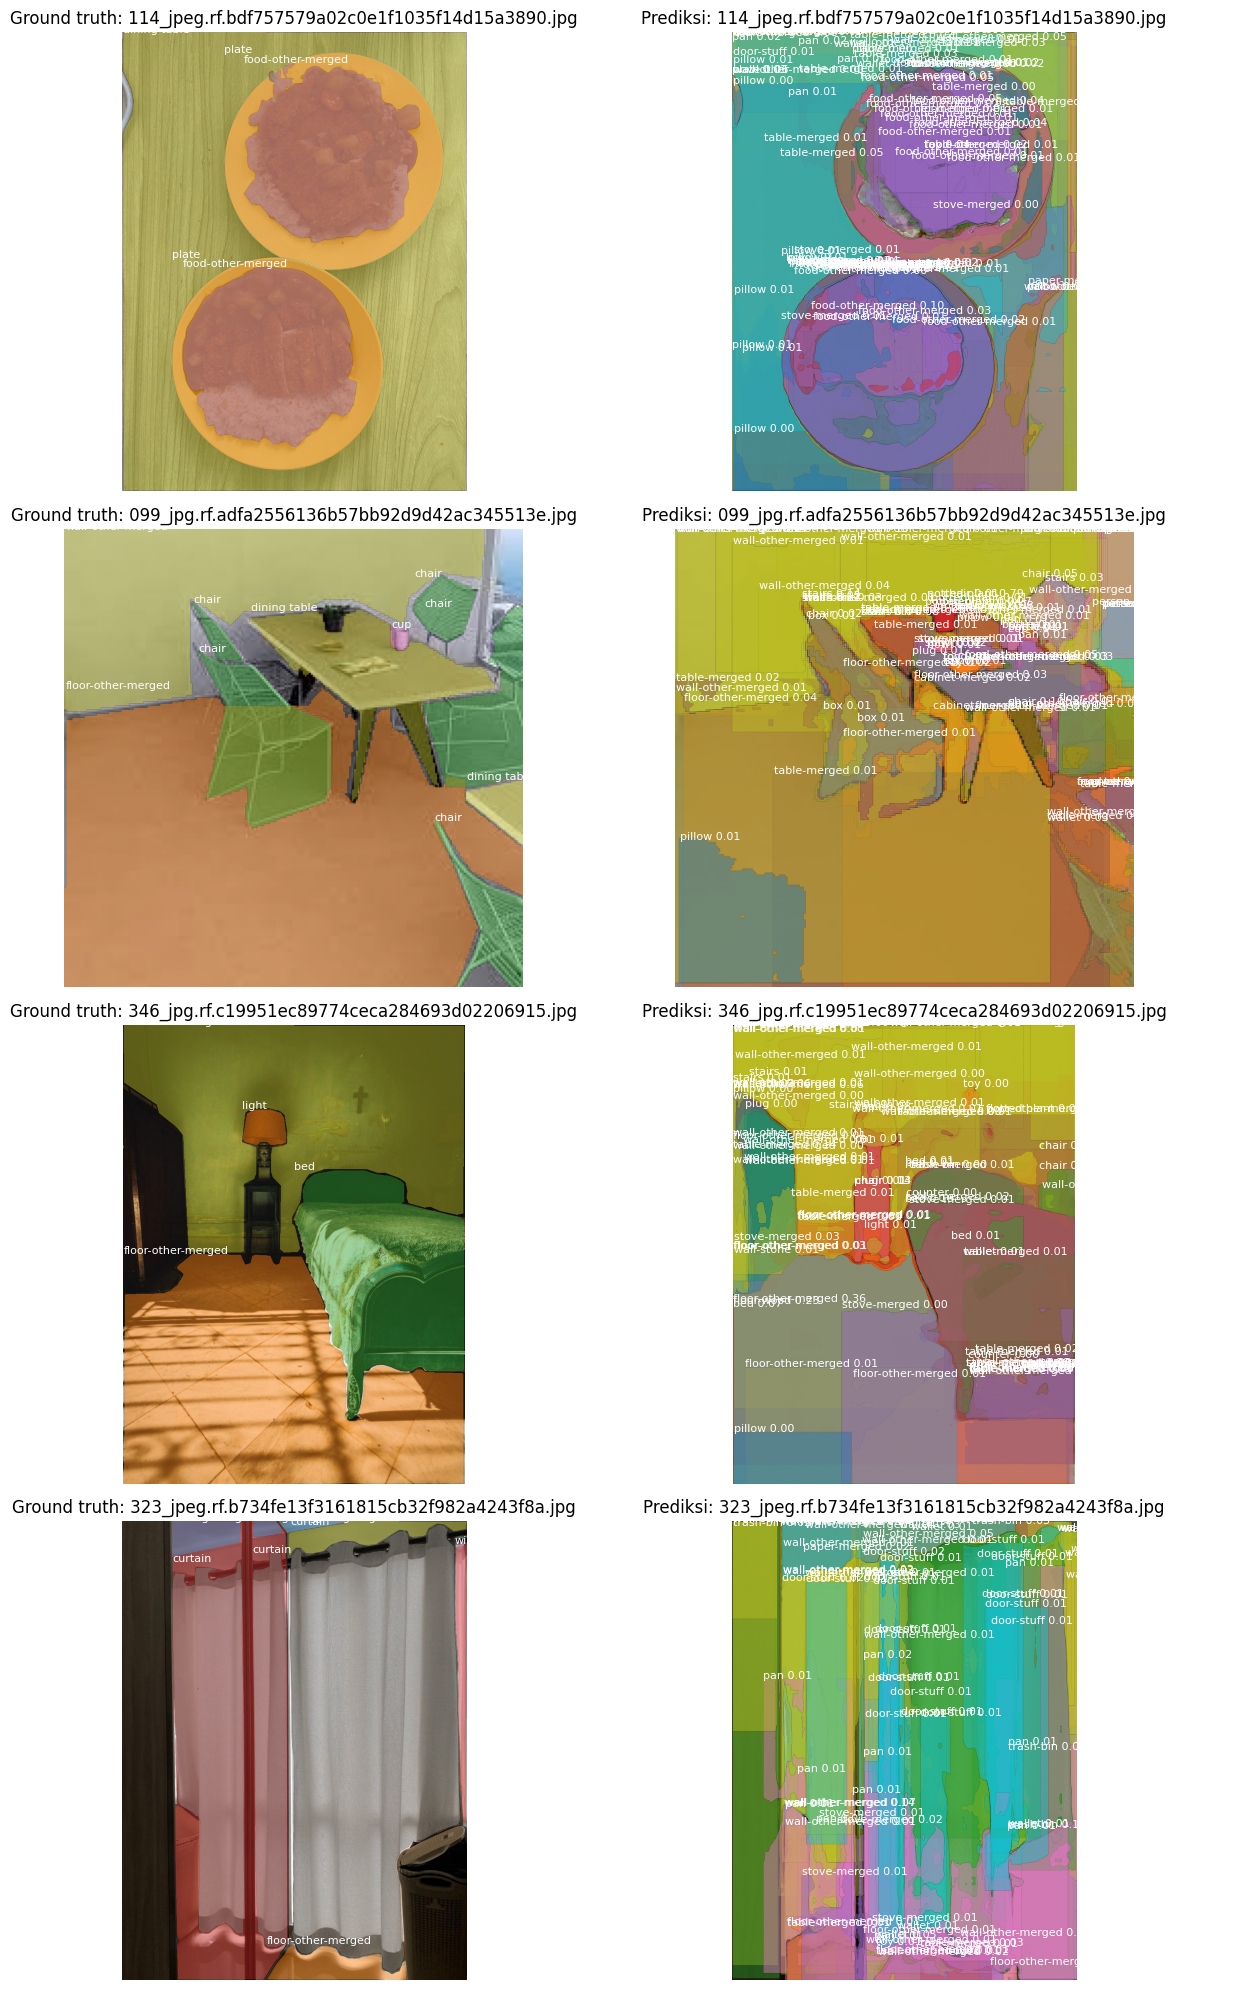

Visualisasi: /kaggle/working/instance_segmentation/yolov8n_pretrained_predictions.png


In [30]:
def show_predictions(split, predictions, run_name, filenames=None, image_ids=None, count=4, output_path=None):
    if not predictions and run_name not in CHECKPOINTS:
        print(f'Checkpoint/prediksi untuk {run_name} belum tersedia; jalankan evaluasi terlebih dahulu.'); return None
    if not predictions and run_name not in PREDICTIONS:
        checkpoint = Path(CHECKPOINTS.get(run_name, ''))
        if not checkpoint.is_file(): print(f'Checkpoint tidak ditemukan untuk {run_name}: {checkpoint}'); return None
        predictions = predict_maskrcnn(checkpoint, split) if run_name.startswith('maskrcnn') else predict_yolo(checkpoint, split)
    grouped = defaultdict(list)
    for prediction in predictions: grouped[prediction['image_id']].append(prediction)
    by_name = {record['file_name']: record for record in split['coco']['images']}
    by_id = {record['id']: record for record in split['coco']['images']}
    if filenames is not None:
        missing = [name for name in filenames if name not in by_name]
        if missing: raise ValueError(f'Nama file tidak ditemukan: {missing}')
        records = [by_name[name] for name in filenames]
    elif image_ids is not None:
        missing = [value for value in image_ids if value not in by_id]
        if missing: raise ValueError(f'Image ID tidak ditemukan: {missing}')
        records = [by_id[value] for value in image_ids]
    else: records = split['coco']['images'][:count]
    if not records: print('Tidak ada foto dipilih.'); return None
    figure, axes = plt.subplots(len(records), 2, figsize=(14, 5 * len(records)), squeeze=False)
    for row, record in enumerate(records):
        with Image.open(image_path(split, record)) as handle: image = handle.convert('RGB')
        for axis, title in ((axes[row, 0], 'Ground truth'), (axes[row, 1], 'Prediksi')):
            axis.imshow(image); axis.set_title(f'{title}: {record["file_name"]}'); axis.axis('off')
        for annotation in [a for a in split['coco']['annotations'] if a['image_id'] == record['id']]:
            mask = split['api'].annToMask(annotation).astype(bool); idx = COCO_TO_LABEL[annotation['category_id']]
            color = plt.cm.tab10(idx % 10)
            axes[row, 0].imshow(np.ma.masked_where(~mask, mask), cmap=plt.matplotlib.colors.ListedColormap([color]), alpha=.45)
            ys, xs = np.where(mask)
            if len(xs): axes[row, 0].text(xs.min(), ys.min(), CLASS_NAMES[idx], color='white', fontsize=8)
        for prediction in grouped[record['id']]:
            mask = mask_utils.decode(prediction['segmentation']).astype(bool); idx = COCO_TO_LABEL[prediction['category_id']]
            color = plt.cm.tab10(idx % 10)
            axes[row, 1].imshow(np.ma.masked_where(~mask, mask), cmap=plt.matplotlib.colors.ListedColormap([color]), alpha=.45)
            ys, xs = np.where(mask)
            if len(xs): axes[row, 1].text(xs.min(), ys.min(), f'{CLASS_NAMES[idx]} {prediction["score"]:.2f}', color='white', fontsize=8)
    figure.tight_layout()
    destination = Path(output_path) if output_path else OUTPUT_ROOT / f'{run_name}_predictions.png'
    destination.parent.mkdir(parents=True, exist_ok=True); figure.savefig(destination, dpi=150, bbox_inches='tight')
    plt.show(); print('Visualisasi:', destination); return destination

SHOW_RUN = next(iter(PREDICTIONS), None)
if SHOW_RUN is None: print('Belum ada checkpoint/prediksi. Jalankan Blok 07 setelah menentukan checkpoint yang tersedia.')
else: show_predictions(SPLITS['test'], PREDICTIONS[SHOW_RUN], SHOW_RUN)


## Tabel hasil akhir
Menggabungkan AP test asli dan pribadi, delta personal−asli, normal/difficult, dan AP per kelas jika tersedia. Nilai yang belum ada diberi status teks, bukan nol. Perbedaan distribusi/dukungan kelas antarset membatasi interpretasi domain shift; delta keseluruhan tidak mengisolasi penyebab.


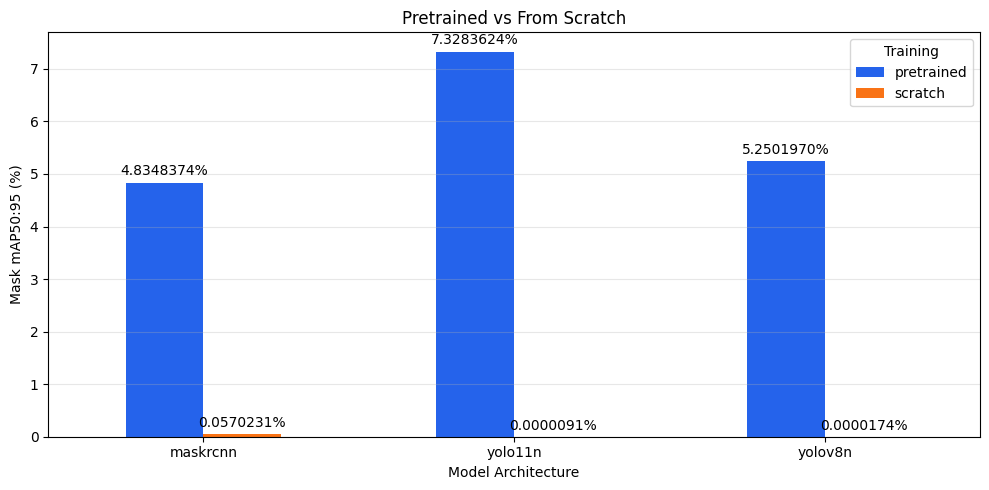

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(RESULTS).T

df["Architecture"] = df.index.str.rsplit("_", n=1).str[0]
df["Training"] = df.index.str.rsplit("_", n=1).str[1]

graph = df.pivot(
    index="Architecture",
    columns="Training",
    values="ap"
).astype(float) * 100

ax = graph.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2563eb", "#f97316"],
    rot=0
)

for bar in ax.containers:
    ax.bar_label(bar, fmt="%.7f%%", padding=3)

plt.title("Pretrained vs From Scratch")
plt.ylabel("Mask mAP50:95 (%)")
plt.xlabel("Model Architecture")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()